<a href="https://colab.research.google.com/github/vitorcassiano1/InteligenciaArtificial_LinguagensFormais_Automatos/blob/main/Sistema_Especialista_DiagnosticoDeComputadores.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Sistema Especialista
## Diagnóstico inicial de problemas em computadores



**Objetivo:** treinar uma árvore de decisão simples e usar sua previsão como fato em um Sistema Especialista que recomenda uma verificação inicial.



# Análise dos aspectos éticos

Privacidade e dados

O sistema utiliza apenas informações sobre o funcionamento do computador, sem solicitar nome, endereço, documentos ou outros dados pessoais. Por exemplo, uma pessoa que utiliza o sistema informa que seu computador não liga. Como essa informação não identifica diretamente o usuário, o risco à privacidade é reduzido. A equipe manterá a coleta limitada aos sintomas necessários para realizar o diagnóstico.

# Declaração sobre o uso de IA

IA presente no projeto: Utilizamos a biblioteca Scikit-learn para criar uma árvore de decisão que prevê possíveis problemas de alimentação ou vídeo. As regras que definem as recomendações foram desenvolvidas pela equipe.

IA utilizada na preparação do trabalho: Utilizamos o ChatGPT para organizar as ideias e auxiliar na análise ética. O conteúdo foi revisado pela equipe, que é responsável pelas informações apresentadas.

# Apresentação do projeto


O projeto consiste em um Sistema Especialista para realizar um diagnóstico inicial de problemas em computadores. O sistema recebe informações sobre o funcionamento do equipamento, como se ele liga, se apresenta imagem e se possui temperatura elevada. A partir dessas informações, uma árvore de decisão, treinada com exemplos simulados, prevê se o possível problema está relacionado à alimentação ou ao vídeo. Em seguida, regras desenvolvidas pela equipe utilizam essa classificação e a temperatura para apresentar recomendações ao usuário. O sistema pode ser utilizado por pessoas que desejam identificar possíveis falhas em seus computadores, sendo também afetados os profissionais responsáveis pela manutenção. As recomendações são hipóteses iniciais e não substituem uma avaliação técnica.

# Reflexão
Acreditamos que o sistema deve ser utilizado apenas como orientação inicial. O argumento mais importante é que a IA pode cometer erros. Para avaliar sua eficiência, devemos testar com mais exemplos e verificar se as recomendações estão corretas.

## 1. Preparar o ambiente

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado
Entradas: o computador liga e apresenta imagem. Rótulo: categoria inicial do problema. Os exemplos são simulados.

In [ ]:
dados = pd.DataFrame({
    "liga": [0,0,0,0,0,0,0,0, 1,1,1,1,1,1,1,1],
    "imagem": [0,0,0,0,0,0,0,0, 0,0,0,0,0,0,0,0],
    "problema": ["alimentacao"] * 8 + ["video"] * 8
})

print(dados.to_string(index=False))
print("\nQuantidade por classe:")
print(dados["problema"].value_counts())

 liga  imagem    problema
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    0       0 alimentacao
    1       0       video
    1       0       video
    1       0       video
    1       0       video
    1       0       video
    1       0       video
    1       0       video
    1       0       video

Quantidade por classe:
problema
alimentacao    8
video          8
Name: count, dtype: int64


## 3. Separar treinamento e teste
`X` contém os atributos e `y` contém o rótulo. Reservamos 25% para teste.

In [ ]:
X = dados[["liga", "imagem"]]
y = dados["problema"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 12 | Teste: 4


## 4. Treinar e avaliar
A árvore aprende com os exemplos de treino. A acurácia e a matriz de confusão comparam as previsões com os rótulos do teste.

Acurácia no teste: 100.0%
             alimentacao  video
alimentacao            2      0
video                  0      2


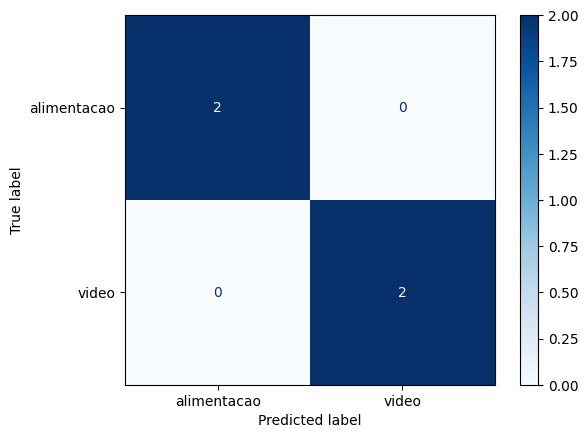

Condições aprendidas:
|--- liga <= 0.50
|   |--- class: alimentacao
|--- liga >  0.50
|   |--- class: video



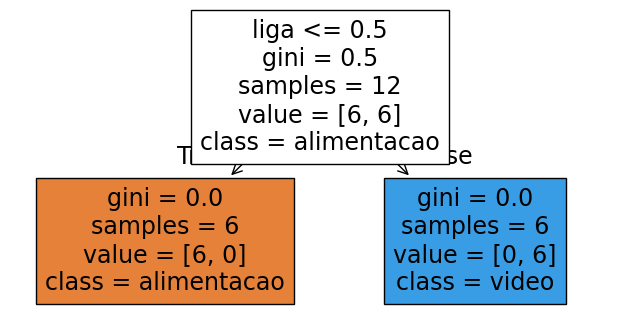

In [ ]:
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)

print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

classes = ["alimentacao", "video"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))

ConfusionMatrixDisplay(matriz, display_labels=classes).plot(cmap="Blues")
plt.show()

print("Condições aprendidas:")
print(export_text(modelo, feature_names=list(X.columns)))

plt.figure(figsize=(8, 4))
plot_tree(modelo, feature_names=list(X.columns),
          class_names=list(modelo.classes_), filled=True)
plt.show()

## 5. Base de conhecimento e motor de inferência

O motor de inferência é responsável por analisar os fatos informados pelo usuário e verificar quais regras da base de conhecimento correspondem à situação apresentada.

No exemplo descrito, o usuário informa que o computador liga, mas não apresenta imagem. O motor de inferência analisa essas informações e verifica as regras disponíveis:
1. A Regra 1 não é acionada, pois o computador liga normalmente.
2. A Regra 2 é acionada, pois o computador liga, mas não apresenta imagem.
3. O sistema conclui que pode existir um problema relacionado ao vídeo e apresenta a recomendação correspondente.
Assim, o motor de inferência utiliza os fatos de entrada para acionar as regras e chegar a uma conclusão.


A árvore prevê uma categoria. A informação sobre temperatura elevada é um fato adicional que ajuda a selecionar a recomendação.

In [ ]:
regras = [
    {"id": "R1", "problema": "alimentacao", "temperatura_alta": False,
     "acao": "Verificar tomada e cabo de energia. Se continuar sem ligar, procurar assistência técnica."},
    {"id": "R2", "problema": "alimentacao", "temperatura_alta": True,
     "acao": "Interromper o uso e procurar assistência técnica."},
    {"id": "R3", "problema": "video", "temperatura_alta": False,
     "acao": "Conferir se o monitor está ligado e se o cabo de vídeo está conectado. Se persistir, solicitar avaliação técnica."},
    {"id": "R4", "problema": "video", "temperatura_alta": True,
     "acao": "Interromper o uso e procurar assistência técnica para avaliar o aquecimento e a ausência de imagem."}
]

def aplicar_regras(problema, temperatura_alta):
    for regra in regras:
        if (regra["problema"] == problema and
            regra["temperatura_alta"] == temperatura_alta):
            return {
                "problema_previsto": problema,
                "regra": regra["id"],
                "recomendacao": regra["acao"]
            }
    raise ValueError("Nenhuma regra compatível.")

## 6. Integrar o modelo ao Sistema Especialista
A função recebe os sintomas, usa a árvore para classificar e aplica a regra correspondente.

In [ ]:
def diagnosticar(liga, imagem, temperatura_alta):
    novo_caso = pd.DataFrame([{"liga": liga, "imagem": imagem}])
    problema = modelo.predict(novo_caso)[0]
    resultado = aplicar_regras(problema, temperatura_alta)
    resultado["aviso"] = "Hipótese didática; não substitui avaliação técnica."
    return resultado

# Três exemplos de consulta
casos = [(0, 0, False), (1, 0, False), (1, 0, True)]

for i, caso in enumerate(casos, 1):
    print(f"\nCASO {i}:")
    for campo, valor in diagnosticar(*caso).items():
        print(f"{campo}: {valor}")


CASO 1:
problema_previsto: alimentacao
regra: R1
recomendacao: Verificar tomada e cabo de energia. Se continuar sem ligar, procurar assistência técnica.
aviso: Hipótese didática; não substitui avaliação técnica.

CASO 2:
problema_previsto: video
regra: R3
recomendacao: Conferir se o monitor está ligado e se o cabo de vídeo está conectado. Se persistir, solicitar avaliação técnica.
aviso: Hipótese didática; não substitui avaliação técnica.

CASO 3:
problema_previsto: video
regra: R4
recomendacao: Interromper o uso e procurar assistência técnica para avaliar o aquecimento e a ausência de imagem.
aviso: Hipótese didática; não substitui avaliação técnica.


## 7. Experimente uma consulta
Altere os valores: `0` = não e `1` = sim.

In [ ]:
liga = 1
imagem = 0
temperatura_alta = False

resultado = diagnosticar(liga, imagem, temperatura_alta)
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

problema_previsto: video
regra: R3
recomendacao: Conferir se o monitor está ligado e se o cabo de vídeo está conectado. Se persistir, solicitar avaliação técnica.
aviso: Hipótese didática; não substitui avaliação técnica.
